In [1]:
# ================================================================
# TAHAP [1]
# IMPORT LIBRARY DAN FUNGSI DASAR
# ================================================================
#
# Tahap ini:
# 1. Mengimpor library yang dibutuhkan.
# 2. Membuat fungsi untuk menampilkan judul.
# 3. Membuat fungsi konversi angka Indonesia.
#
# Jalankan tahap ini terlebih dahulu sebelum tahap lainnya.
# ================================================================

import os
import io
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from google.colab import files


def judul(teks):
    """
    Menampilkan judul bagian agar keluaran mudah dibaca.
    """
    print("\n" + "=" * 78)
    print(teks)
    print("=" * 78)


def konversi_angka(nilai):
    """
    Mengubah berbagai format angka menjadi float.

    Contoh format yang didukung:
    - Rp 1.500.000
    - 1.500.000,50
    - 1,500,000.50
    - 75,5
    - 80%
    """

    # Jika nilainya kosong, kembalikan NaN
    if pd.isna(nilai):
        return np.nan

    # Jika sudah berupa angka, langsung ubah menjadi float
    if isinstance(
        nilai,
        (int, float, np.integer, np.floating)
    ):
        return float(nilai)

    # Mengubah nilai menjadi teks dan membersihkan spasi
    teks = str(nilai).strip()

    # Teks berikut dianggap sebagai nilai kosong
    if teks.lower() in ["", "nan", "none", "null", "-"]:
        return np.nan

    # Menghapus simbol yang umum ditemukan pada dataset
    teks = teks.replace("Rp", "")
    teks = teks.replace("rp", "")
    teks = teks.replace("%", "")
    teks = teks.replace(" ", "")

    # Format memiliki titik dan koma
    if "." in teks and "," in teks:

        # Format Indonesia: 1.500.000,50
        if teks.rfind(",") > teks.rfind("."):
            teks = teks.replace(".", "")
            teks = teks.replace(",", ".")

        # Format internasional: 1,500,000.50
        else:
            teks = teks.replace(",", "")

    # Format hanya memiliki koma
    elif "," in teks:
        bagian = teks.split(",")

        # Contoh 75,5 dianggap desimal
        if len(bagian) == 2 and len(bagian[-1]) <= 2:
            teks = teks.replace(",", ".")

        # Contoh 1,500 dianggap pemisah ribuan
        else:
            teks = teks.replace(",", "")

    # Contoh 1.500.000
    elif teks.count(".") > 1:
        teks = teks.replace(".", "")

    # Contoh 1.500 dianggap 1500
    elif teks.count(".") == 1:
        sebelum, sesudah = teks.split(".")

        if (
            len(sesudah) == 3
            and sebelum.replace("-", "").isdigit()
            and sesudah.isdigit()
            and not sebelum.lstrip("-").startswith("0")
        ):
            teks = sebelum + sesudah

    try:
        return float(teks)

    except ValueError:
        # Nilai gagal dikonversi akan ditangkap pada tahap validasi
        return np.nan


print("Tahap [1] berhasil dijalankan.")
print("Library dan fungsi dasar sudah tersedia.")

Tahap [1] berhasil dijalankan.
Library dan fungsi dasar sudah tersedia.


In [2]:
# ================================================================
# TAHAP [2]
# UPLOAD DAN MEMBACA DATASET
# ================================================================
#
# Format yang didukung:
# - CSV
# - XLSX
# - XLS
#
# Dataset minimal harus mempunyai:
# 1. Satu kolom nama alternatif.
# 2. Satu atau lebih kolom nilai kriteria.
# ================================================================

judul("UPLOAD DATA ALTERNATIF")

print("Unggah satu file CSV, XLSX, atau XLS.")

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("Tidak ada file yang diunggah.")

# Mengambil file pertama yang diunggah
nama_file_input = list(uploaded.keys())[0]
isi_file = uploaded[nama_file_input]
ekstensi = os.path.splitext(nama_file_input)[1].lower()


# ------------------------------------------------
# Membaca file CSV
# ------------------------------------------------

if ekstensi == ".csv":

    try:
        # sep=None digunakan agar pemisah koma atau titik koma
        # dapat dideteksi secara otomatis
        df_asli = pd.read_csv(
            io.BytesIO(isi_file),
            sep=None,
            engine="python"
        )

    except UnicodeDecodeError:
        # Alternatif encoding jika UTF-8 gagal
        df_asli = pd.read_csv(
            io.BytesIO(isi_file),
            sep=None,
            engine="python",
            encoding="latin-1"
        )


# ------------------------------------------------
# Membaca file Excel
# ------------------------------------------------

elif ekstensi in [".xlsx", ".xls"]:

    file_excel = pd.ExcelFile(
        io.BytesIO(isi_file)
    )

    print("\nDaftar sheet:")

    for nomor, nama_sheet in enumerate(
        file_excel.sheet_names,
        start=1
    ):
        print(f"{nomor}. {nama_sheet}")

    # Jika hanya ada satu sheet, langsung digunakan
    if len(file_excel.sheet_names) == 1:
        sheet_dipilih = file_excel.sheet_names[0]

    # Jika terdapat beberapa sheet, pengguna memilih
    else:
        while True:
            pilihan_sheet = input(
                "\nMasukkan nomor sheet: "
            ).strip()

            if pilihan_sheet.isdigit():
                nomor_sheet = int(pilihan_sheet)

                if 1 <= nomor_sheet <= len(
                    file_excel.sheet_names
                ):
                    sheet_dipilih = (
                        file_excel.sheet_names[
                            nomor_sheet - 1
                        ]
                    )
                    break

            print("Nomor sheet tidak valid.")

    df_asli = pd.read_excel(
        io.BytesIO(isi_file),
        sheet_name=sheet_dipilih
    )


else:
    raise ValueError(
        "Format file tidak didukung. "
        "Gunakan CSV, XLSX, atau XLS."
    )


# Membersihkan nama kolom
df_asli.columns = [
    str(kolom).strip()
    for kolom in df_asli.columns
]

# Menghapus baris dan kolom yang seluruh isinya kosong
df_asli = df_asli.dropna(how="all")
df_asli = df_asli.dropna(axis=1, how="all")
df_asli = df_asli.reset_index(drop=True)

# Validasi dasar
if df_asli.empty:
    raise ValueError("Dataset tidak memiliki data.")

if len(df_asli.columns) < 2:
    raise ValueError(
        "Dataset minimal harus memiliki satu kolom alternatif "
        "dan satu kolom kriteria."
    )

print(f"\nFile berhasil dibaca: {nama_file_input}")
print(f"Jumlah baris: {len(df_asli)}")
print(f"Jumlah kolom: {len(df_asli.columns)}")

display(df_asli)


UPLOAD DATA ALTERNATIF
Unggah satu file CSV, XLSX, atau XLS.


Saving Latihan Soal_VIKOR.csv to Latihan Soal_VIKOR.csv

File berhasil dibaca: Latihan Soal_VIKOR.csv
Jumlah baris: 4
Jumlah kolom: 6


,Alternatif,C1_Harga,C2_Nilai_Investasi,C3_Daya_Dukung,C4_Prioritas,C5_Ketersediaan
0,A1 Mobil Box,420,75,3,1,3
1,A2 Tanah Gudang,580,220,2,3,2
2,A3 Maintenance TI,350,80,4,2,1
3,A4 Produk Baru,410,170,3,4,2


In [3]:
# ================================================================
# TAHAP [3]
# MEMILIH KOLOM ALTERNATIF DAN KRITERIA
# ================================================================
#
# Pengguna dapat:
# 1. Menentukan kolom yang berisi nama alternatif.
# 2. Menggunakan seluruh calon kriteria.
# 3. Memilih hanya beberapa kolom sebagai kriteria.
# ================================================================

judul("PEMILIHAN KOLOM ALTERNATIF")

print("Daftar kolom dataset:")

for nomor, kolom in enumerate(
    df_asli.columns,
    start=1
):
    print(f"{nomor}. {kolom}")

while True:
    pilihan = input(
        "\nMasukkan nomor kolom nama alternatif: "
    ).strip()

    if pilihan.isdigit():
        nomor_kolom = int(pilihan)

        if 1 <= nomor_kolom <= len(df_asli.columns):
            kolom_alternatif = (
                df_asli.columns[nomor_kolom - 1]
            )
            break

    print("Pilihan tidak valid.")


judul("PEMILIHAN KRITERIA")

# Semua kolom selain alternatif menjadi calon kriteria
calon_kriteria = [
    kolom
    for kolom in df_asli.columns
    if kolom != kolom_alternatif
]

for nomor, kolom in enumerate(
    calon_kriteria,
    start=1
):
    print(f"{nomor}. {kolom}")

print("\nTekan Enter untuk menggunakan seluruh kolom.")
print("Atau masukkan nomor seperti: 1,2,4")

while True:
    pilihan = input("\nPilih kriteria: ").strip()

    # Enter kosong berarti memilih semua kriteria
    if pilihan == "":
        daftar_kriteria = calon_kriteria.copy()
        break

    try:
        nomor_dipilih = [
            int(item.strip())
            for item in pilihan.split(",")
        ]

        # Menghapus nomor duplikat tanpa mengubah urutan
        nomor_dipilih = list(
            dict.fromkeys(nomor_dipilih)
        )

        if len(nomor_dipilih) == 0:
            raise ValueError

        if not all(
            1 <= nomor <= len(calon_kriteria)
            for nomor in nomor_dipilih
        ):
            raise ValueError

        daftar_kriteria = [
            calon_kriteria[nomor - 1]
            for nomor in nomor_dipilih
        ]

        break

    except ValueError:
        print(
            "Pilihan tidak valid. "
            "Gunakan format seperti 1,2,4."
        )


# Hanya mengambil kolom yang digunakan
df = df_asli[
    [kolom_alternatif] + daftar_kriteria
].copy()

# Membersihkan nama alternatif
# NaN tidak diubah menjadi string agar dapat diketahui saat validasi
df[kolom_alternatif] = df[
    kolom_alternatif
].apply(
    lambda nilai:
    nilai if pd.isna(nilai)
    else str(nilai).strip()
)

# Mengubah seluruh nilai kriteria menjadi numerik
for kriteria in daftar_kriteria:
    df[kriteria] = df[kriteria].apply(
        konversi_angka
    )

print("\nKolom alternatif:", kolom_alternatif)
print("Kriteria terpilih:", daftar_kriteria)

display(df)


PEMILIHAN KOLOM ALTERNATIF
Daftar kolom dataset:
1. Alternatif
2. C1_Harga
3. C2_Nilai_Investasi
4. C3_Daya_Dukung
5. C4_Prioritas
6. C5_Ketersediaan

Masukkan nomor kolom nama alternatif: 1

PEMILIHAN KRITERIA
1. C1_Harga
2. C2_Nilai_Investasi
3. C3_Daya_Dukung
4. C4_Prioritas
5. C5_Ketersediaan

Tekan Enter untuk menggunakan seluruh kolom.
Atau masukkan nomor seperti: 1,2,4

Pilih kriteria: 1,2,3,4,5

Kolom alternatif: Alternatif
Kriteria terpilih: ['C1_Harga', 'C2_Nilai_Investasi', 'C3_Daya_Dukung', 'C4_Prioritas', 'C5_Ketersediaan']


,Alternatif,C1_Harga,C2_Nilai_Investasi,C3_Daya_Dukung,C4_Prioritas,C5_Ketersediaan
0,A1 Mobil Box,420.0,75.0,3.0,1.0,3.0
1,A2 Tanah Gudang,580.0,220.0,2.0,3.0,2.0
2,A3 Maintenance TI,350.0,80.0,4.0,2.0,1.0
3,A4 Produk Baru,410.0,170.0,3.0,4.0,2.0


In [4]:
# ================================================================
# TAHAP [4]
# VALIDASI DATASET
# ================================================================
#
# Pemeriksaan yang dilakukan:
# 1. Minimal terdapat dua alternatif.
# 2. Minimal terdapat satu kriteria.
# 3. Nama alternatif tidak kosong.
# 4. Nama alternatif tidak duplikat.
# 5. Nilai kriteria tidak kosong.
# 6. Nilai kriteria harus numerik.
# 7. Nilai kriteria tidak boleh tak terbatas.
# ================================================================

judul("VALIDASI DATASET")

masalah = []

# VIKOR membutuhkan perbandingan beberapa alternatif
if len(df) < 2:
    masalah.append(
        "VIKOR membutuhkan minimal dua alternatif."
    )

if len(daftar_kriteria) < 1:
    masalah.append(
        "Minimal harus terdapat satu kriteria."
    )


# ------------------------------------------------
# Memeriksa nama alternatif kosong
# ------------------------------------------------

alternatif_kosong = df[
    kolom_alternatif
].isna()

if alternatif_kosong.any():
    nomor_baris = (
        df.index[alternatif_kosong] + 2
    ).tolist()

    masalah.append(
        f"Nama alternatif kosong pada baris sekitar {nomor_baris} (perkiraan baris di file)."
    )


nama_alternatif_bersih = (
    df[kolom_alternatif]
    .fillna("")
    .astype(str)
    .str.strip()
)

if (nama_alternatif_bersih == "").any():
    nomor_baris = (
        df.index[nama_alternatif_bersih == ""] + 2
    ).tolist()

    masalah.append(
        f"Nama alternatif kosong pada baris sekitar {nomor_baris} (perkiraan baris di file)."
    )


# ------------------------------------------------
# Memeriksa duplikasi nama alternatif
# ------------------------------------------------

duplikasi = nama_alternatif_bersih[
    nama_alternatif_bersih.duplicated(
        keep=False
    )
].unique()

if len(duplikasi) > 0:
    masalah.append(
        "Nama alternatif harus unik. "
        f"Duplikasi ditemukan: {list(duplikasi)}"
    )


# ------------------------------------------------
# Memeriksa setiap nilai kriteria
# ------------------------------------------------

for kriteria in daftar_kriteria:

    nilai_kosong = df[kriteria].isna()

    if nilai_kosong.any():
        nomor_baris = (
            df.index[nilai_kosong] + 2
        ).tolist()

        masalah.append(
            f"Kriteria '{kriteria}' memiliki nilai kosong "
            f"atau nonnumerik pada baris sekitar {nomor_baris} (perkiraan baris di file)."
        )

    nilai_valid = df[kriteria].dropna()

    if np.isinf(nilai_valid).any():
        masalah.append(
            f"Kriteria '{kriteria}' memiliki nilai tak terbatas."
        )


# ------------------------------------------------
# Menampilkan hasil validasi
# ------------------------------------------------

if masalah:
    print("Data belum dapat diproses:\n")

    for nomor, pesan in enumerate(
        masalah,
        start=1
    ):
        print(f"{nomor}. {pesan}")

    raise ValueError(
        "Perbaiki dataset, kemudian jalankan kembali "
        "mulai Tahap [2]."
    )


# Daftar nama alternatif digunakan pada tahap selanjutnya
nama_alternatif = (
    df[kolom_alternatif]
    .astype(str)
    .tolist()
)

print("Data valid.")
print(f"Jumlah alternatif: {len(df)}")
print(f"Jumlah kriteria: {len(daftar_kriteria)}")

display(df)


VALIDASI DATASET
Data valid.
Jumlah alternatif: 4
Jumlah kriteria: 5


,Alternatif,C1_Harga,C2_Nilai_Investasi,C3_Daya_Dukung,C4_Prioritas,C5_Ketersediaan
0,A1 Mobil Box,420.0,75.0,3.0,1.0,3.0
1,A2 Tanah Gudang,580.0,220.0,2.0,3.0,2.0
2,A3 Maintenance TI,350.0,80.0,4.0,2.0,1.0
3,A4 Produk Baru,410.0,170.0,3.0,4.0,2.0


In [5]:
# ================================================================
# TAHAP [5]
# INPUT BOBOT DAN JENIS KRITERIA
# ================================================================
#
# Benefit:
# Semakin besar nilainya, semakin baik.
#
# Cost:
# Semakin kecil nilainya, semakin baik.
#
# Bobot boleh menggunakan skala bebas, misalnya:
# - 5, 4, 3
# - 40, 35, 25
#
# Bobot akan dinormalisasi agar totalnya menjadi 1.
# ================================================================

judul("BOBOT DAN JENIS KRITERIA")

print("Benefit: semakin besar semakin baik.")
print("Cost   : semakin kecil semakin baik.")
print("Bobot harus lebih besar dari nol.")

bobot_input = {}
jenis_kriteria = {}

for nomor, kriteria in enumerate(
    daftar_kriteria,
    start=1
):
    print(f"\nKriteria {nomor}: {kriteria}")

    # ------------------------------------------------
    # Input bobot
    # ------------------------------------------------

    while True:
        nilai_input = input(
            f"Bobot '{kriteria}': "
        ).strip().replace(",", ".")

        try:
            nilai_bobot = float(nilai_input)

            if not math.isfinite(nilai_bobot):
                print(
                    "Bobot harus berupa angka yang valid."
                )
                continue

            if nilai_bobot <= 0:
                print(
                    "Bobot harus lebih besar dari nol."
                )
                continue

            bobot_input[kriteria] = nilai_bobot
            break

        except ValueError:
            print("Bobot harus berupa angka.")

    # ------------------------------------------------
    # Input jenis kriteria
    # ------------------------------------------------

    while True:
        jenis_input = input(
            f"Jenis '{kriteria}' [benefit/cost]: "
        ).strip().lower()

        if jenis_input in ["benefit", "b"]:
            jenis_kriteria[kriteria] = "benefit"
            break

        elif jenis_input in ["cost", "c"]:
            jenis_kriteria[kriteria] = "cost"
            break

        else:
            print(
                "Masukkan benefit/b atau cost/c."
            )


# Mengubah bobot menjadi Series
bobot_awal = pd.Series(
    bobot_input,
    dtype=float
)

# Normalisasi bobot
bobot_normalisasi = (
    bobot_awal / bobot_awal.sum()
)

# Membuat array bobot sesuai urutan kriteria
array_bobot = np.array([
    bobot_normalisasi[kriteria]
    for kriteria in daftar_kriteria
])

# Membuat tabel konfigurasi
konfigurasi = pd.DataFrame({
    "Kriteria": daftar_kriteria,
    "Bobot Awal": [
        bobot_awal[kriteria]
        for kriteria in daftar_kriteria
    ],
    "Bobot Normalisasi": [
        bobot_normalisasi[kriteria]
        for kriteria in daftar_kriteria
    ],
    "Persentase": [
        bobot_normalisasi[kriteria] * 100
        for kriteria in daftar_kriteria
    ],
    "Jenis": [
        jenis_kriteria[kriteria]
        for kriteria in daftar_kriteria
    ]
})

display(konfigurasi.round(6))

print(
    "\nTotal bobot awal:",
    round(bobot_awal.sum(), 6)
)

print(
    "Total bobot normalisasi:",
    round(bobot_normalisasi.sum(), 6)
)


BOBOT DAN JENIS KRITERIA
Benefit: semakin besar semakin baik.
Cost   : semakin kecil semakin baik.
Bobot harus lebih besar dari nol.

Kriteria 1: C1_Harga
Bobot 'C1_Harga': 20
Jenis 'C1_Harga' [benefit/cost]: c

Kriteria 2: C2_Nilai_Investasi
Bobot 'C2_Nilai_Investasi': 15
Jenis 'C2_Nilai_Investasi' [benefit/cost]: b

Kriteria 3: C3_Daya_Dukung
Bobot 'C3_Daya_Dukung': 30
Jenis 'C3_Daya_Dukung' [benefit/cost]: b

Kriteria 4: C4_Prioritas
Bobot 'C4_Prioritas': 25
Jenis 'C4_Prioritas' [benefit/cost]: c

Kriteria 5: C5_Ketersediaan
Bobot 'C5_Ketersediaan': 10
Jenis 'C5_Ketersediaan' [benefit/cost]: b


,Kriteria,Bobot Awal,Bobot Normalisasi,Persentase,Jenis
0,C1_Harga,20.0,0.20,20.0,cost
1,C2_Nilai_Investasi,15.0,0.15,15.0,benefit
2,C3_Daya_Dukung,30.0,0.30,30.0,benefit
3,C4_Prioritas,25.0,0.25,25.0,cost
4,C5_Ketersediaan,10.0,0.10,10.0,benefit



Total bobot awal: 100.0
Total bobot normalisasi: 1.0


In [6]:
# ================================================================
# TAHAP [6]
# MENENTUKAN NILAI TERBAIK DAN TERBURUK
# ================================================================
#
# Pada VIKOR:
#
# KRITERIA BENEFIT
# - Nilai terbaik  = nilai maksimum
# - Nilai terburuk = nilai minimum
#
# KRITERIA COST
# - Nilai terbaik  = nilai minimum
# - Nilai terburuk = nilai maksimum
#
# Penentuan ini penting karena normalisasi VIKOR mengukur
# jarak setiap alternatif terhadap nilai ideal.
# ================================================================

judul("NILAI TERBAIK DAN TERBURUK")

nilai_terbaik = {}
nilai_terburuk = {}
kriteria_konstan = []

for kriteria in daftar_kriteria:

    nilai_minimum = df[kriteria].min()
    nilai_maksimum = df[kriteria].max()

    if jenis_kriteria[kriteria] == "benefit":

        # Benefit: nilai besar lebih baik
        nilai_terbaik[kriteria] = nilai_maksimum
        nilai_terburuk[kriteria] = nilai_minimum

    else:

        # Cost: nilai kecil lebih baik
        nilai_terbaik[kriteria] = nilai_minimum
        nilai_terburuk[kriteria] = nilai_maksimum

    # Mendeteksi kriteria yang tidak memiliki variasi
    if np.isclose(
        nilai_terbaik[kriteria],
        nilai_terburuk[kriteria]
    ):
        kriteria_konstan.append(kriteria)


tabel_ideal = pd.DataFrame({
    "Kriteria": daftar_kriteria,
    "Jenis": [
        jenis_kriteria[kriteria]
        for kriteria in daftar_kriteria
    ],
    "Nilai Terbaik (f*)": [
        nilai_terbaik[kriteria]
        for kriteria in daftar_kriteria
    ],
    "Nilai Terburuk (f-)": [
        nilai_terburuk[kriteria]
        for kriteria in daftar_kriteria
    ]
})

display(tabel_ideal)


if len(kriteria_konstan) > 0:
    print(
        "\nPeringatan: kriteria berikut mempunyai nilai "
        "yang sama pada seluruh alternatif:"
    )

    for kriteria in kriteria_konstan:
        print(f"- {kriteria}")

    print(
        "\nKriteria tersebut tidak dapat membedakan alternatif. "
        "Nilai normalisasinya akan dibuat 0."
    )


NILAI TERBAIK DAN TERBURUK


,Kriteria,Jenis,Nilai Terbaik (f*),Nilai Terburuk (f-)
0,C1_Harga,cost,350.0,580.0
1,C2_Nilai_Investasi,benefit,220.0,75.0
2,C3_Daya_Dukung,benefit,4.0,2.0
3,C4_Prioritas,cost,1.0,4.0
4,C5_Ketersediaan,benefit,3.0,1.0


In [7]:
# ================================================================
# TAHAP [7]
# NORMALISASI MATRIKS KEPUTUSAN VIKOR
# ================================================================
#
# Rumus umum:
#
# r_ij = (f*_j - f_ij) / (f*_j - f-_j)
#
# Keterangan:
# r_ij = jarak ternormalisasi alternatif i pada kriteria j
# f*_j = nilai terbaik kriteria j
# f-_j = nilai terburuk kriteria j
# f_ij = nilai alternatif i pada kriteria j
#
# Dengan penentuan f* dan f- berdasarkan benefit/cost:
# - Nilai terbaik menghasilkan r_ij = 0
# - Nilai terburuk menghasilkan r_ij = 1
#
# Karena itu, nilai normalisasi yang lebih kecil lebih baik.
# ================================================================

judul("NORMALISASI MATRIKS KEPUTUSAN")

normalisasi_vikor = pd.DataFrame(
    index=nama_alternatif,
    columns=daftar_kriteria,
    dtype=float
)

# Menyimpan detail perhitungan
detail_normalisasi = []

for indeks, baris in df.iterrows():

    alternatif = str(
        baris[kolom_alternatif]
    )

    for kriteria in daftar_kriteria:

        f_terbaik = nilai_terbaik[kriteria]
        f_terburuk = nilai_terburuk[kriteria]
        nilai = baris[kriteria]

        penyebut = (
            f_terbaik - f_terburuk
        )

        # Jika seluruh nilai sama, jarak dibuat 0
        if np.isclose(penyebut, 0):
            nilai_normalisasi = 0.0

        else:
            nilai_normalisasi = (
                (f_terbaik - nilai)
                / penyebut
            )

        # Mengatasi efek floating point sangat kecil
        if np.isclose(nilai_normalisasi, 0):
            nilai_normalisasi = 0.0

        if np.isclose(nilai_normalisasi, 1):
            nilai_normalisasi = 1.0

        normalisasi_vikor.at[
            alternatif,
            kriteria
        ] = nilai_normalisasi

        detail_normalisasi.append({
            "Alternatif": alternatif,
            "Kriteria": kriteria,
            "Jenis": jenis_kriteria[kriteria],
            "Nilai Awal": nilai,
            "Nilai Terbaik": f_terbaik,
            "Nilai Terburuk": f_terburuk,
            "Nilai Normalisasi": nilai_normalisasi
        })


df_detail_normalisasi = pd.DataFrame(
    detail_normalisasi
)

print("Detail normalisasi:")
display(df_detail_normalisasi.round(6))

print("\nMatriks normalisasi VIKOR:")
display(normalisasi_vikor.round(6))


NORMALISASI MATRIKS KEPUTUSAN
Detail normalisasi:


,Alternatif,Kriteria,Jenis,Nilai Awal,Nilai Terbaik,Nilai Terburuk,Nilai Normalisasi
0,A1 Mobil Box,C1_Harga,cost,420.0,350.0,580.0,0.304348
1,A1 Mobil Box,C2_Nilai_Investasi,benefit,75.0,220.0,75.0,1.000000
2,A1 Mobil Box,C3_Daya_Dukung,benefit,3.0,4.0,2.0,0.500000
3,A1 Mobil Box,C4_Prioritas,cost,1.0,1.0,4.0,0.000000
4,A1 Mobil Box,C5_Ketersediaan,benefit,3.0,3.0,1.0,0.000000
5,A2 Tanah Gudang,C1_Harga,cost,580.0,350.0,580.0,1.000000
6,A2 Tanah Gudang,C2_Nilai_Investasi,benefit,220.0,220.0,75.0,0.000000
7,A2 Tanah Gudang,C3_Daya_Dukung,benefit,2.0,4.0,2.0,1.000000
8,A2 Tanah Gudang,C4_Prioritas,cost,3.0,1.0,4.0,0.666667
9,A2 Tanah Gudang,C5_Ketersediaan,benefit,2.0,3.0,1.0,0.500000



Matriks normalisasi VIKOR:


,C1_Harga,C2_Nilai_Investasi,C3_Daya_Dukung,C4_Prioritas,C5_Ketersediaan
A1 Mobil Box,0.304348,1.000000,0.5,0.000000,0.0
A2 Tanah Gudang,1.000000,0.000000,1.0,0.666667,0.5
A3 Maintenance TI,0.000000,0.965517,0.0,0.333333,1.0
A4 Produk Baru,0.260870,0.344828,0.5,1.000000,0.5


In [8]:
# ================================================================
# TAHAP [8]
# MATRIKS NORMALISASI TERBOBOT
# ================================================================
#
# Rumus:
#
# t_ij = w_j x r_ij
#
# Keterangan:
# t_ij = nilai normalisasi terbobot
# w_j  = bobot normalisasi kriteria
# r_ij = nilai normalisasi VIKOR
#
# Matriks ini digunakan untuk menghitung nilai S dan R.
# ================================================================

judul("MATRIKS NORMALISASI TERBOBOT")

matriks_normalisasi = (
    normalisasi_vikor[
        daftar_kriteria
    ].to_numpy(dtype=float)
)

# Setiap kolom dikalikan dengan bobot kriterianya
matriks_terbobot = (
    matriks_normalisasi * array_bobot
)

df_terbobot = pd.DataFrame(
    matriks_terbobot,
    index=nama_alternatif,
    columns=daftar_kriteria
)

display(df_terbobot.round(6))


MATRIKS NORMALISASI TERBOBOT


,C1_Harga,C2_Nilai_Investasi,C3_Daya_Dukung,C4_Prioritas,C5_Ketersediaan
A1 Mobil Box,0.060870,0.150000,0.15,0.000000,0.00
A2 Tanah Gudang,0.200000,0.000000,0.30,0.166667,0.05
A3 Maintenance TI,0.000000,0.144828,0.00,0.083333,0.10
A4 Produk Baru,0.052174,0.051724,0.15,0.250000,0.05


In [9]:
# ================================================================
# TAHAP [9]
# MENGHITUNG NILAI S DAN R
# ================================================================
#
# Nilai S atau group utility:
#
# S_i = SUM(w_j x r_ij)
#
# Nilai R atau individual regret:
#
# R_i = MAX(w_j x r_ij)
#
# Interpretasi:
# - Nilai S kecil menunjukkan jarak total yang lebih kecil
#   terhadap solusi ideal.
# - Nilai R kecil menunjukkan penyesalan maksimum yang lebih kecil.
#
# Nilai yang digunakan tetap dalam presisi penuh.
# Pembulatan hanya dilakukan saat ditampilkan.
# ================================================================

judul("PERHITUNGAN NILAI S DAN R")

# S adalah jumlah setiap baris
nilai_S = np.sum(
    matriks_terbobot,
    axis=1
)

# R adalah nilai maksimum setiap baris
nilai_R = np.max(
    matriks_terbobot,
    axis=1
)

df_S_R = pd.DataFrame({
    "Alternatif": nama_alternatif,
    "Nilai S": nilai_S,
    "Nilai R": nilai_R
})

# Menampilkan detail perhitungan
for i, alternatif in enumerate(nama_alternatif):

    kontribusi = matriks_terbobot[i]

    bentuk_S = " + ".join(
        f"{nilai:.6f}"
        for nilai in kontribusi
    )

    bentuk_R = " ; ".join(
        f"{nilai:.6f}"
        for nilai in kontribusi
    )

    print(f"\nAlternatif {alternatif}:")

    print(
        f"S_{alternatif} = {bentuk_S} "
        f"= {nilai_S[i]:.6f}"
    )

    print(
        f"R_{alternatif} = MAX "
        f"{{{bentuk_R}}} "
        f"= {nilai_R[i]:.6f}"
    )


print("\nHasil nilai S dan R:")
display(df_S_R.round(6))


PERHITUNGAN NILAI S DAN R

Alternatif A1 Mobil Box:
S_A1 Mobil Box = 0.060870 + 0.150000 + 0.150000 + 0.000000 + 0.000000 = 0.360870
R_A1 Mobil Box = MAX {0.060870 ; 0.150000 ; 0.150000 ; 0.000000 ; 0.000000} = 0.150000

Alternatif A2 Tanah Gudang:
S_A2 Tanah Gudang = 0.200000 + 0.000000 + 0.300000 + 0.166667 + 0.050000 = 0.716667
R_A2 Tanah Gudang = MAX {0.200000 ; 0.000000 ; 0.300000 ; 0.166667 ; 0.050000} = 0.300000

Alternatif A3 Maintenance TI:
S_A3 Maintenance TI = 0.000000 + 0.144828 + 0.000000 + 0.083333 + 0.100000 = 0.328161
R_A3 Maintenance TI = MAX {0.000000 ; 0.144828 ; 0.000000 ; 0.083333 ; 0.100000} = 0.144828

Alternatif A4 Produk Baru:
S_A4 Produk Baru = 0.052174 + 0.051724 + 0.150000 + 0.250000 + 0.050000 = 0.553898
R_A4 Produk Baru = MAX {0.052174 ; 0.051724 ; 0.150000 ; 0.250000 ; 0.050000} = 0.250000

Hasil nilai S dan R:


,Alternatif,Nilai S,Nilai R
0,A1 Mobil Box,0.360870,0.150000
1,A2 Tanah Gudang,0.716667,0.300000
2,A3 Maintenance TI,0.328161,0.144828
3,A4 Produk Baru,0.553898,0.250000


In [10]:
# ================================================================
# TAHAP [10]
# INPUT PARAMETER STRATEGI V
# ================================================================
#
# Parameter V berada pada rentang 0 sampai 1.
#
# V = 0.5
# Memberikan keseimbangan antara group utility dan regret.
#
# V > 0.5
# Lebih menekankan keuntungan mayoritas atau group utility.
#
# V < 0.5
# Lebih menekankan minimisasi penyesalan individu.
#
# Nilai bawaan yang umum digunakan adalah 0.5.
# Tekan Enter jika ingin menggunakan nilai 0.5.
# ================================================================

judul("PARAMETER STRATEGI VIKOR")

while True:
    input_v = input(
        "Masukkan nilai V antara 0 dan 1 "
        "[Enter = 0.5]: "
    ).strip()

    # Jika dikosongkan, gunakan nilai standar 0.5
    if input_v == "":
        nilai_v = 0.5
        break

    input_v = input_v.replace(",", ".")

    try:
        nilai_v = float(input_v)

        if not math.isfinite(nilai_v):
            print("Nilai V harus berupa angka yang valid.")
            continue

        if not 0 <= nilai_v <= 1:
            print("Nilai V harus berada antara 0 dan 1.")
            continue

        break

    except ValueError:
        print("Nilai V harus berupa angka.")


print(f"\nParameter V yang digunakan: {nilai_v}")

if np.isclose(nilai_v, 0.5):
    print(
        "Strategi seimbang antara group utility dan regret."
    )

elif nilai_v > 0.5:
    print(
        "Strategi lebih menekankan group utility."
    )

else:
    print(
        "Strategi lebih menekankan individual regret."
    )


PARAMETER STRATEGI VIKOR
Masukkan nilai V antara 0 dan 1 [Enter = 0.5]: 

Parameter V yang digunakan: 0.5
Strategi seimbang antara group utility dan regret.


In [11]:
# ================================================================
# TAHAP [11]
# MENGHITUNG INDEKS VIKOR Q
# ================================================================
#
# Rumus:
#
# Q_i =
# V x ((S_i - S*) / (S- - S*))
# +
# (1 - V) x ((R_i - R*) / (R- - R*))
#
# Keterangan:
# S* = nilai S terbaik, yaitu minimum
# S- = nilai S terburuk, yaitu maksimum
# R* = nilai R terbaik, yaitu minimum
# R- = nilai R terburuk, yaitu maksimum
#
# Nilai Q yang lebih kecil lebih baik.
# ================================================================

judul("PERHITUNGAN INDEKS VIKOR Q")

# Nilai terbaik dan terburuk S
S_terbaik = np.min(nilai_S)
S_terburuk = np.max(nilai_S)

# Nilai terbaik dan terburuk R
R_terbaik = np.min(nilai_R)
R_terburuk = np.max(nilai_R)

print(f"S terbaik  (S*): {S_terbaik:.6f}")
print(f"S terburuk (S-): {S_terburuk:.6f}")
print(f"R terbaik  (R*): {R_terbaik:.6f}")
print(f"R terburuk (R-): {R_terburuk:.6f}")

# Menyiapkan array nilai Q
nilai_Q = np.zeros(len(nama_alternatif))

# Menyimpan komponen S dan R
komponen_S = np.zeros(len(nama_alternatif))
komponen_R = np.zeros(len(nama_alternatif))


for i, alternatif in enumerate(nama_alternatif):

    # Menghindari pembagian dengan nol jika seluruh nilai S sama
    if np.isclose(
        S_terburuk,
        S_terbaik
    ):
        komponen_S[i] = 0.0

    else:
        komponen_S[i] = (
            (nilai_S[i] - S_terbaik)
            / (S_terburuk - S_terbaik)
        )

    # Menghindari pembagian dengan nol jika seluruh nilai R sama
    if np.isclose(
        R_terburuk,
        R_terbaik
    ):
        komponen_R[i] = 0.0

    else:
        komponen_R[i] = (
            (nilai_R[i] - R_terbaik)
            / (R_terburuk - R_terbaik)
        )

    # Menghitung indeks Q
    nilai_Q[i] = (
        nilai_v * komponen_S[i]
        + (1 - nilai_v) * komponen_R[i]
    )

    print(f"\nAlternatif {alternatif}:")

    print(
        f"Komponen S = "
        f"({nilai_S[i]:.6f} - {S_terbaik:.6f}) / "
        f"({S_terburuk:.6f} - {S_terbaik:.6f}) "
        f"= {komponen_S[i]:.6f}"
    )

    print(
        f"Komponen R = "
        f"({nilai_R[i]:.6f} - {R_terbaik:.6f}) / "
        f"({R_terburuk:.6f} - {R_terbaik:.6f}) "
        f"= {komponen_R[i]:.6f}"
    )

    print(
        f"Q_{alternatif} = "
        f"({nilai_v:.4f} x {komponen_S[i]:.6f}) + "
        f"({1 - nilai_v:.4f} x {komponen_R[i]:.6f}) "
        f"= {nilai_Q[i]:.6f}"
    )


df_Q = pd.DataFrame({
    "Alternatif": nama_alternatif,
    "Komponen S": komponen_S,
    "Komponen R": komponen_R,
    "Nilai Q": nilai_Q
})

print("\nHasil indeks VIKOR:")
display(df_Q.round(6))


PERHITUNGAN INDEKS VIKOR Q
S terbaik  (S*): 0.328161
S terburuk (S-): 0.716667
R terbaik  (R*): 0.144828
R terburuk (R-): 0.300000

Alternatif A1 Mobil Box:
Komponen S = (0.360870 - 0.328161) / (0.716667 - 0.328161) = 0.084191
Komponen R = (0.150000 - 0.144828) / (0.300000 - 0.144828) = 0.033333
Q_A1 Mobil Box = (0.5000 x 0.084191) + (0.5000 x 0.033333) = 0.058762

Alternatif A2 Tanah Gudang:
Komponen S = (0.716667 - 0.328161) / (0.716667 - 0.328161) = 1.000000
Komponen R = (0.300000 - 0.144828) / (0.300000 - 0.144828) = 1.000000
Q_A2 Tanah Gudang = (0.5000 x 1.000000) + (0.5000 x 1.000000) = 1.000000

Alternatif A3 Maintenance TI:
Komponen S = (0.328161 - 0.328161) / (0.716667 - 0.328161) = 0.000000
Komponen R = (0.144828 - 0.144828) / (0.300000 - 0.144828) = 0.000000
Q_A3 Maintenance TI = (0.5000 x 0.000000) + (0.5000 x 0.000000) = 0.000000

Alternatif A4 Produk Baru:
Komponen S = (0.553898 - 0.328161) / (0.716667 - 0.328161) = 0.581039
Komponen R = (0.250000 - 0.144828) / (0.300000

,Alternatif,Komponen S,Komponen R,Nilai Q
0,A1 Mobil Box,0.084191,0.033333,0.058762
1,A2 Tanah Gudang,1.000000,1.000000,1.000000
2,A3 Maintenance TI,0.000000,0.000000,0.000000
3,A4 Produk Baru,0.581039,0.677778,0.629409


In [12]:
# ================================================================
# TAHAP [12]
# PERANGKINGAN DAN SOLUSI KOMPROMI VIKOR
# ================================================================
#
# Peringkat utama ditentukan berdasarkan nilai Q terkecil.
#
# VIKOR juga mempunyai dua syarat solusi kompromi:
#
# SYARAT 1 - ACCEPTABLE ADVANTAGE
#
# Q(A2) - Q(A1) >= DQ
#
# DQ = 1 / (m - 1)
#
# A1 = alternatif peringkat pertama berdasarkan Q
# A2 = alternatif peringkat kedua berdasarkan Q
# m  = jumlah alternatif
#
# SYARAT 2 - ACCEPTABLE STABILITY
#
# Alternatif A1 juga harus berada pada peringkat pertama
# berdasarkan nilai S atau nilai R.
#
# Jika kedua syarat terpenuhi:
# A1 menjadi solusi kompromi tunggal.
#
# Jika syarat advantage tidak terpenuhi:
# Beberapa alternatif dapat menjadi solusi kompromi.
# ================================================================

judul("PERANGKINGAN DAN SOLUSI KOMPROMI")

hasil_vikor = pd.DataFrame({
    "Alternatif": nama_alternatif,
    "Nilai S": nilai_S,
    "Nilai R": nilai_R,
    "Nilai Q": nilai_Q
})

# Ranking berdasarkan S, R, dan Q
# Nilai yang lebih kecil memperoleh peringkat lebih baik
hasil_vikor["Peringkat S"] = (
    hasil_vikor["Nilai S"]
    .rank(method="min", ascending=True)
    .astype(int)
)

hasil_vikor["Peringkat R"] = (
    hasil_vikor["Nilai R"]
    .rank(method="min", ascending=True)
    .astype(int)
)

hasil_vikor["Peringkat Q"] = (
    hasil_vikor["Nilai Q"]
    .rank(method="min", ascending=True)
    .astype(int)
)

# Mengurutkan hasil berdasarkan nilai Q
hasil_vikor = hasil_vikor.sort_values(
    by=[
        "Nilai Q",
        "Nilai S",
        "Nilai R",
        "Alternatif"
    ],
    ascending=[
        True,
        True,
        True,
        True
    ]
).reset_index(drop=True)

display(hasil_vikor.round(6))


# ------------------------------------------------
# Menghitung batas acceptable advantage
# ------------------------------------------------

jumlah_alternatif = len(hasil_vikor)

if jumlah_alternatif > 1:
    DQ = 1 / (jumlah_alternatif - 1)
else:
    DQ = 0.0

alternatif_A1 = hasil_vikor.iloc[0]
alternatif_A2 = hasil_vikor.iloc[1]

selisih_Q = (
    alternatif_A2["Nilai Q"]
    - alternatif_A1["Nilai Q"]
)

# Syarat 1: acceptable advantage
syarat_1 = selisih_Q >= DQ - 1e-12

# Syarat 2: acceptable stability
syarat_2 = (
    alternatif_A1["Peringkat S"] == 1
    or alternatif_A1["Peringkat R"] == 1
)


print("\nAlternatif peringkat pertama:")
print(
    f"{alternatif_A1['Alternatif']} "
    f"dengan Q = {alternatif_A1['Nilai Q']:.6f}"
)

print("\nNilai DQ:")
print(
    f"DQ = 1 / ({jumlah_alternatif} - 1) "
    f"= {DQ:.6f}"
)

print("\nPemeriksaan acceptable advantage:")
print(
    f"Q(A2) - Q(A1) = "
    f"{alternatif_A2['Nilai Q']:.6f} - "
    f"{alternatif_A1['Nilai Q']:.6f} "
    f"= {selisih_Q:.6f}"
)

print(
    "Syarat 1:",
    "Terpenuhi" if syarat_1 else "Tidak terpenuhi"
)

print("\nPemeriksaan acceptable stability:")
print(
    f"Peringkat S A1 = "
    f"{alternatif_A1['Peringkat S']}"
)

print(
    f"Peringkat R A1 = "
    f"{alternatif_A1['Peringkat R']}"
)

print(
    "Syarat 2:",
    "Terpenuhi" if syarat_2 else "Tidak terpenuhi"
)


# ------------------------------------------------
# Menentukan solusi kompromi
# ------------------------------------------------

if syarat_1 and syarat_2:

    # Kedua syarat terpenuhi
    solusi_kompromi = hasil_vikor.iloc[[0]].copy()

    keterangan_solusi = (
        "Solusi kompromi tunggal karena acceptable advantage "
        "dan acceptable stability terpenuhi."
    )

elif not syarat_1:

    # Jika acceptable advantage tidak terpenuhi,
    # pilih seluruh alternatif A(k) yang memenuhi:
    # Q(Ak) - Q(A1) < DQ

    batas_Q = (
        alternatif_A1["Nilai Q"] + DQ
    )

    solusi_kompromi = hasil_vikor[
        hasil_vikor["Nilai Q"] < batas_Q - 1e-12
    ].copy()

    # Pengaman agar minimal A1 dan A2 tercakup
    if len(solusi_kompromi) < 2:
        solusi_kompromi = hasil_vikor.iloc[:2].copy()

    keterangan_solusi = (
        "Terdapat beberapa solusi kompromi karena "
        "acceptable advantage tidak terpenuhi."
    )

else:

    # Advantage terpenuhi tetapi stability tidak terpenuhi
    solusi_kompromi = hasil_vikor.iloc[:2].copy()

    keterangan_solusi = (
        "Alternatif A1 dan A2 menjadi solusi kompromi karena "
        "acceptable stability tidak terpenuhi."
    )


print("\nKesimpulan solusi kompromi:")
print(keterangan_solusi)

display(
    solusi_kompromi[
        [
            "Alternatif",
            "Nilai S",
            "Nilai R",
            "Nilai Q",
            "Peringkat Q"
        ]
    ].round(6)
)


PERANGKINGAN DAN SOLUSI KOMPROMI


,Alternatif,Nilai S,Nilai R,Nilai Q,Peringkat S,Peringkat R,Peringkat Q
0,A3 Maintenance TI,0.328161,0.144828,0.000000,1,1,1
1,A1 Mobil Box,0.360870,0.150000,0.058762,2,2,2
2,A4 Produk Baru,0.553898,0.250000,0.629409,3,3,3
3,A2 Tanah Gudang,0.716667,0.300000,1.000000,4,4,4



Alternatif peringkat pertama:
A3 Maintenance TI dengan Q = 0.000000

Nilai DQ:
DQ = 1 / (4 - 1) = 0.333333

Pemeriksaan acceptable advantage:
Q(A2) - Q(A1) = 0.058762 - 0.000000 = 0.058762
Syarat 1: Tidak terpenuhi

Pemeriksaan acceptable stability:
Peringkat S A1 = 1
Peringkat R A1 = 1
Syarat 2: Terpenuhi

Kesimpulan solusi kompromi:
Terdapat beberapa solusi kompromi karena acceptable advantage tidak terpenuhi.


,Alternatif,Nilai S,Nilai R,Nilai Q,Peringkat Q
0,A3 Maintenance TI,0.328161,0.144828,0.000000,1
1,A1 Mobil Box,0.360870,0.150000,0.058762,2



VISUALISASI HASIL VIKOR


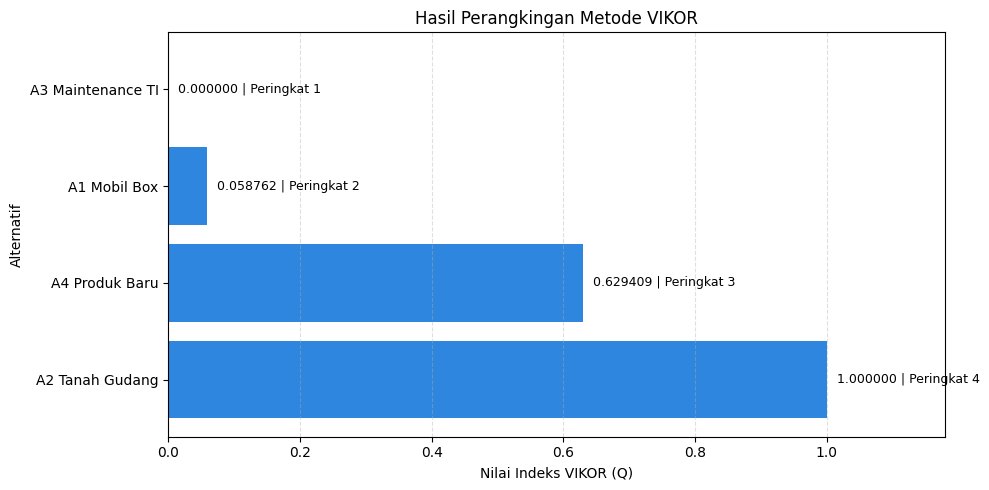

In [13]:
# ================================================================
# TAHAP [13]
# VISUALISASI DAN EKSPOR HASIL
# ================================================================
#
# Tahap ini:
# 1. Membuat grafik nilai Q.
# 2. Menyimpan seluruh tahapan ke file Excel.
# 3. Mengunduh file hasil.
#
# Dalam VIKOR, nilai Q yang lebih kecil lebih baik.
# ================================================================

judul("VISUALISASI HASIL VIKOR")

jumlah_data = len(hasil_vikor)
tinggi_grafik = max(5, jumlah_data * 0.55)

# Alternatif peringkat pertama diberi warna hijau
warna = [
    "#27AE60"
    if peringkat == 1
    else "#2E86DE"
    for peringkat in hasil_vikor["Peringkat Q"]
]

plt.figure(
    figsize=(10, tinggi_grafik)
)

batang = plt.barh(
    hasil_vikor["Alternatif"].astype(str),
    hasil_vikor["Nilai Q"],
    color=warna
)

plt.xlabel("Nilai Indeks VIKOR (Q)")
plt.ylabel("Alternatif")
plt.title("Hasil Perangkingan Metode VIKOR")

# Peringkat terbaik ditempatkan di atas
plt.gca().invert_yaxis()

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

nilai_Q_maksimum = max(
    1.0,
    hasil_vikor["Nilai Q"].max()
)

plt.xlim(
    0,
    nilai_Q_maksimum * 1.18
)

# Menampilkan nilai Q dan peringkat
for batang_item, nilai, peringkat in zip(
    batang,
    hasil_vikor["Nilai Q"],
    hasil_vikor["Peringkat Q"]
):
    plt.text(
        nilai + nilai_Q_maksimum * 0.015,
        batang_item.get_y()
        + batang_item.get_height() / 2,
        f"{nilai:.6f} | Peringkat {peringkat}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [ ]:
# ================================================================
# MENYIMPAN HASIL KE EXCEL
# ================================================================

judul("MENYIMPAN HASIL")

nama_file_hasil = "hasil_perhitungan_vikor.xlsx"

# Informasi parameter V
tabel_parameter = pd.DataFrame({
    "Parameter": [
        "Nilai V",
        "S Terbaik",
        "S Terburuk",
        "R Terbaik",
        "R Terburuk",
        "DQ",
        "Selisih Q(A2)-Q(A1)",
        "Acceptable Advantage",
        "Acceptable Stability"
    ],
    "Nilai": [
        nilai_v,
        S_terbaik,
        S_terburuk,
        R_terbaik,
        R_terburuk,
        DQ,
        selisih_Q,
        "Terpenuhi" if syarat_1 else "Tidak terpenuhi",
        "Terpenuhi" if syarat_2 else "Tidak terpenuhi"
    ]
})

# Tabel solusi kompromi
tabel_solusi = solusi_kompromi.copy()
tabel_solusi["Keterangan"] = keterangan_solusi


with pd.ExcelWriter(
    nama_file_hasil,
    engine="openpyxl"
) as writer:

    # Data awal
    df.to_excel(
        writer,
        sheet_name="Data Awal",
        index=False
    )

    # Konfigurasi kriteria
    konfigurasi.to_excel(
        writer,
        sheet_name="Konfigurasi",
        index=False
    )

    # Nilai ideal terbaik dan terburuk
    tabel_ideal.to_excel(
        writer,
        sheet_name="Nilai Ideal",
        index=False
    )

    # Detail normalisasi
    df_detail_normalisasi.to_excel(
        writer,
        sheet_name="Detail Normalisasi",
        index=False
    )

    # Matriks normalisasi
    normalisasi_vikor.to_excel(
        writer,
        sheet_name="Normalisasi"
    )

    # Matriks terbobot
    df_terbobot.to_excel(
        writer,
        sheet_name="Normalisasi Terbobot"
    )

    # Nilai S dan R
    df_S_R.to_excel(
        writer,
        sheet_name="Nilai S dan R",
        index=False
    )

    # Nilai Q
    df_Q.to_excel(
        writer,
        sheet_name="Nilai Q",
        index=False
    )

    # Parameter VIKOR
    tabel_parameter.to_excel(
        writer,
        sheet_name="Parameter VIKOR",
        index=False
    )

    # Hasil ranking
    hasil_vikor.to_excel(
        writer,
        sheet_name="Hasil Ranking",
        index=False
    )

    # Solusi kompromi
    tabel_solusi.to_excel(
        writer,
        sheet_name="Solusi Kompromi",
        index=False
    )

    # Merapikan seluruh sheet
    workbook = writer.book

    for nama_sheet in workbook.sheetnames:

        worksheet = workbook[nama_sheet]

        # Membekukan baris judul
        worksheet.freeze_panes = "A2"

        # Mengatur lebar kolom otomatis
        for kumpulan_sel in worksheet.columns:

            panjang_maksimum = 0
            huruf_kolom = (
                kumpulan_sel[0].column_letter
            )

            for sel in kumpulan_sel:

                if sel.value is not None:
                    panjang_maksimum = max(
                        panjang_maksimum,
                        len(str(sel.value))
                    )

            worksheet.column_dimensions[
                huruf_kolom
            ].width = min(
                panjang_maksimum + 2,
                45
            )


print(f"File berhasil dibuat: {nama_file_hasil}")

# Mengunduh hasil secara otomatis
files.download(nama_file_hasil)